# 01. Data, revisions and the real-time problem

**Question for the project**: how accurately can UK quarterly GDP growth be estimated *before* the
Office for National Statistics (ONS) publishes its first estimate, and does regularised regression
on a wide panel of indicators help?

This notebook covers the data and the feature of macroeconomic data that drives every design choice:
**GDP figures are revised after publication**, and so are the indicators used to predict them.

| Source | What | Real-time history? |
|---|---|---|
| ONS real-time database (ABMI) | every published estimate of quarterly GDP since 1961 | yes, 746 vintages |
| ONS revisions triangles | monthly growth of the Index of Services, Production, Manufacturing and monthly GDP, as published each month | yes, from 1998 (IoP), 2001 (IoS), 2018 (monthly GDP) |
| ONS time series (mgdp, diop, drsi, mret, lms, mm23) | monthly GDP by sector, manufacturing detail, retail, trade, labour market, prices | latest vintage only |
| Bank of England database | Bank Rate, gilt yields, sterling, mortgage rates and approvals, M4 | latest vintage (rarely revised) |

In [1]:
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from nowcast.config import HORIZON_LABELS

In [2]:
from nowcast import data
from nowcast.config import INDICATORS
cat = pd.DataFrame([(i.code, i.name, i.group, i.transform, i.lag) for i in INDICATORS],
                   columns=["code", "name", "group", "transform", "publication lag (months)"])
print(cat.groupby("group").size().to_string())
cat.head(12)

group
Labour market                             8
Manufacturing detail (latest vintage)    13
Money and markets                         9
Output (latest vintage)                  22
Output (real time)                        3
Prices                                    5
Retail                                    4
Trade                                    10


,code,name,group,transform,publication lag (months)
0,RT_IOS,Index of Services (real time),Output (real time),rt,2
1,RT_IOP,Index of Production (real time),Output (real time),rt,2
2,RT_IOM,Index of Manufacturing (real time),Output (real time),rt,2
3,ECY2,Monthly GDP (GVA),Output (latest vintage),dlog,2
4,ECY3,Agriculture,Output (latest vintage),dlog,2
5,ECY4,Production,Output (latest vintage),dlog,2
6,ECY5,Mining and quarrying,Output (latest vintage),dlog,2
7,ECY6,Manufacturing,Output (latest vintage),dlog,2
8,ECY7,Electricity and gas,Output (latest vintage),dlog,2
9,ECY8,Water and waste,Output (latest vintage),dlog,2


## GDP revisions: the target itself moves

Quarters 2006Q1-2026Q2 excluding COVID: 76
mean revision (latest - first): +0.083 pp
root mean square revision:      0.365 pp
sd of first estimates:          0.534 pp
corr(first, latest):            0.817


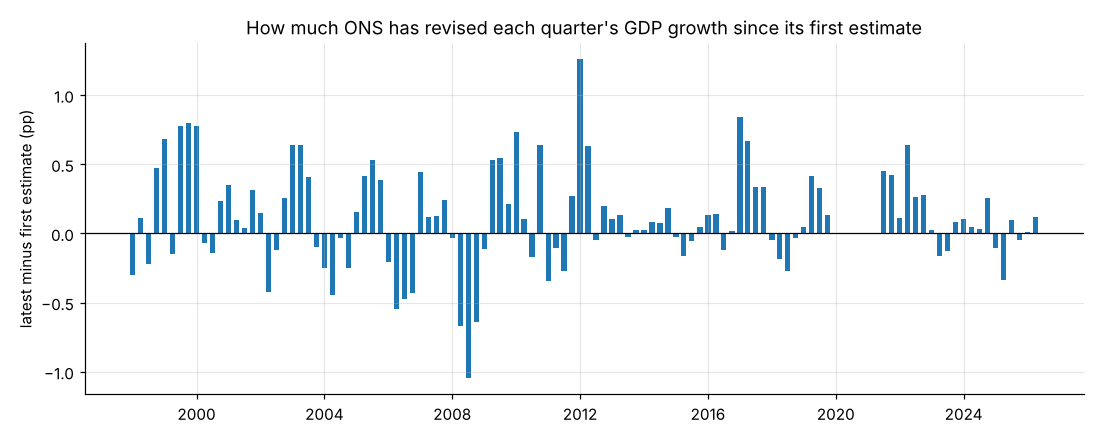

In [3]:
fl = pd.read_csv(T / "gdp_revisions.csv", index_col=0)
fl.index = pd.PeriodIndex(fl.index, freq="Q")
ev = fl.loc["2006Q1":"2026Q2"].drop(pd.period_range("2020Q1", "2021Q2", freq="Q"))
print(f"Quarters 2006Q1-2026Q2 excluding COVID: {len(ev)}")
print(f"mean revision (latest - first): {ev.revision.mean():+.3f} pp")
print(f"root mean square revision:      {np.sqrt((ev.revision**2).mean()):.3f} pp")
print(f"sd of first estimates:          {ev.first_estimate.std():.3f} pp")
print(f"corr(first, latest):            {ev.first_estimate.corr(ev.latest_estimate):.3f}")
display(Image(FIG / "gdp_revisions.png"))

Revisions are of the same order as the quarter-to-quarter variation in the first estimates
themselves. Any nowcast judged against the first estimate is partly judged against noise that ONS
later removes, and any model trained on *today's* data has seen those later revisions.

## The publication calendar changed in 2018
Until mid-2018 ONS published a preliminary GDP estimate about 25 days after the quarter; since then
the first estimate comes about 40 days after, informed by three months of monthly GDP data.

In [4]:
from nowcast.features import GDPVintages
gdp = GDPVintages(data.load_gdp_vintages())
lag = pd.Series({q: (gdp.first_vintage[q] - q.asfreq("M", "end")).n
                 for q in gdp.first.index if q >= pd.Period("1998Q1", "Q")})
lag.groupby(lag.index.year).agg(lambda s: s.mode()[0]).rename("months after quarter end").to_frame().T

,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
months after quarter end,2,2,2,2,1,1,1,1,1,1,...,1,2,2,2,2,2,2,2,2,2


## Monthly output data are revised too
The ONS revisions triangles show each month's growth as first published and as it stands now.

In [5]:
rt = data.load_realtime()
rows = []
for sid, g in rt.groupby("series"):
    first = g.sort_values("vintage").groupby("month").value.first()
    last = g.sort_values("vintage").groupby("month").value.last()
    d = (last - first).loc["2006-01":"2025-12"]
    d = d[~((d.index >= pd.Period("2020-01", "M")) & (d.index <= pd.Period("2021-06", "M")))]
    rows.append(dict(series=sid, months=len(d), mean_abs_revision=d.abs().mean(),
                     rms_revision=np.sqrt((d**2).mean()), sd_first=first.loc[d.index].std()))
pd.DataFrame(rows).set_index("series").round(3)

,months,mean_abs_revision,rms_revision,sd_first
series,,,,
RT_IOM,222,0.746,0.976,0.943
RT_IOP,222,0.649,0.833,0.817
RT_IOS,222,0.302,0.403,0.415
RT_MGDP,222,0.181,0.234,0.428


**Design consequences**
1. The target is the **first estimate** (what markets, the Bank and the Treasury react to on
   publication day); accuracy against the latest estimate is reported alongside.
2. Output indicators come from the **revisions triangles**: each month's figure as published at
   the time. Today's revised monthly GDP series is used only in an experiment that measures how much
   look-ahead bias it would introduce (notebook 06).
3. GDP lags used as predictors are taken from the vintage available at each nowcast date.